In [60]:
# ==============================================================================
# DATA CLEANING, VALIDATION & STANDARDIZATION
# ==============================================================================
import pandas as pd
import numpy as np
import os

# Load dataset
df = pd.read_csv('/content/Nassau Candy Distributor.csv')

print(f"Initial Record Count: {len(df)}")

# 1. Standardize string labels & clean whitespace
str_cols = ['Division', 'Region', 'Country/Region', 'City', 'State/Province', 'Product ID', 'Product Name', 'Ship Mode']
for col in str_cols:
    df[col] = df[col].astype(str).str.strip()

# 2. Convert and validate date fields
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)
df['YearMonth'] = df['Order Date'].dt.to_period('M')

# 3. Data Cleaning: Validate costs and sales, remove zero or negative sales/units
clean_mask = (df['Sales'] > 0) & (df['Units'] > 0) & (df['Cost'] >= 0) & (df['Gross Profit'].notnull())
df_clean = df[clean_mask].copy()

# 4. Handle any missing units / verify schema
df_clean['Units'] = df_clean['Units'].fillna(1).astype(int)

# 5. Core Feature Engineering
df_clean['Gross Margin (%)'] = (df_clean['Gross Profit'] / df_clean['Sales']) * 100
df_clean['Profit per Unit'] = df_clean['Gross Profit'] / df_clean['Units']
df_clean['Unit Price'] = df_clean['Sales'] / df_clean['Units']
df_clean['Unit Cost'] = df_clean['Cost'] / df_clean['Units']

print(f"Cleaned Valid Records: {len(df_clean)}")
print(f"Divisions detected: {df_clean['Division'].unique().tolist()}")

Initial Record Count: 10194
Cleaned Valid Records: 10194
Divisions detected: ['Chocolate', 'Other', 'Sugar']


In [61]:
# ==============================================================================
# EXECUTIVE & PRODUCT-LEVEL KPI CALCULATION
# ==============================================================================
total_distributor_sales = df_clean['Sales'].sum()
total_distributor_profit = df_clean['Gross Profit'].sum()
total_distributor_cost = df_clean['Cost'].sum()
total_distributor_units = df_clean['Units'].sum()

print("=" * 65)
print("EXECUTIVE OVERALL METRICS")
print("=" * 65)
print(f"Total Sales Revenue        : ${total_distributor_sales:,.2f}")
print(f"Total Cost of Goods Sold   : ${total_distributor_cost:,.2f}")
print(f"Total Gross Profit         : ${total_distributor_profit:,.2f}")
print(f"Overall Gross Margin       : {(total_distributor_profit / total_distributor_sales) * 100:.2f}%")
print(f"Total Units Distributed    : {total_distributor_units:,}")

# Product-level aggregation
prod_kpi = df_clean.groupby(['Product ID', 'Product Name', 'Division']).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Cost=('Cost', 'sum'),
    Total_Gross_Profit=('Gross Profit', 'sum'),
    Total_Units=('Units', 'sum')
).reset_index()

# Compute requested project KPIs
prod_kpi['Gross Margin (%)'] = (prod_kpi['Total_Gross_Profit'] / prod_kpi['Total_Sales']) * 100
prod_kpi['Profit per Unit'] = prod_kpi['Total_Gross_Profit'] / prod_kpi['Total_Units']
prod_kpi['Revenue Contribution (%)'] = (prod_kpi['Total_Sales'] / total_distributor_sales) * 100
prod_kpi['Profit Contribution (%)'] = (prod_kpi['Total_Gross_Profit'] / total_distributor_profit) * 100

# Margin Volatility (Standard Deviation of margin over time periods)
prod_volatility = df_clean.groupby('Product Name').apply(
    lambda grp: grp.groupby('YearMonth')[['Gross Profit', 'Sales']].apply(
        lambda m: (m['Gross Profit'].sum() / m['Sales'].sum()) * 100
    ).std(),
    include_groups=False
).fillna(0).reset_index(name='Margin Volatility (Std Dev)')

prod_kpi = prod_kpi.merge(prod_volatility, on='Product Name')

print("\n--- KPI SCORECARD (TOP 10 BY PROFIT CONTRIBUTION) ---")
display(prod_kpi.sort_values(by='Profit Contribution (%)', ascending=False).head(10)[[
    'Product Name', 'Division', 'Total_Sales', 'Gross Margin (%)',
    'Profit per Unit', 'Revenue Contribution (%)', 'Profit Contribution (%)', 'Margin Volatility (Std Dev)'
]])

EXECUTIVE OVERALL METRICS
Total Sales Revenue        : $141,783.63
Total Cost of Goods Sold   : $48,340.83
Total Gross Profit         : $93,442.80
Overall Gross Margin       : 65.91%
Total Units Distributed    : 38,654

--- KPI SCORECARD (TOP 10 BY PROFIT CONTRIBUTION) ---


,Product Name,Division,Total_Sales,Gross Margin (%),Profit per Unit,Revenue Contribution (%),Profit Contribution (%),Margin Volatility (Std Dev)
3,Wonka Bar -Scrumdiddlyumptious,Chocolate,27874.80,69.444444,2.50,19.660098,20.715882,3.135922e-14
4,Wonka Bar - Triple Dazzle Caramel,Chocolate,28485.00,65.333333,2.45,20.090472,19.916141,2.256682e-14
1,Wonka Bar - Milk Chocolate,Chocolate,26867.75,64.923077,2.11,18.949825,18.667431,1.068385e-14
2,Wonka Bar - Nutty Crunch Surprise,Chocolate,23574.95,71.346705,2.49,16.627413,18.000263,1.068385e-14
0,Wonka Bar - Fudge Mallows,Chocolate,24890.40,66.666667,2.40,17.555200,17.758030,1.649822e-14
8,Lickable Wallpaper,Other,7860.00,50.000000,10.00,5.543658,4.205782,0.000000e+00
6,Wonka Gum,Other,597.50,52.000000,0.65,0.421417,0.332503,3.312923e-15
9,Everlasting Gobstopper,Sugar,130.00,80.000000,8.00,0.091689,0.111298,0.000000e+00
7,Kazookles,Other,1205.75,7.692308,0.25,0.850416,0.099259,3.632560e-15
11,Hair Toffee,Sugar,76.50,77.777778,3.50,0.053955,0.063675,0.000000e+00


In [62]:
# ==============================================================================
# PORTFOLIO SEGMENTATION & DIVISION COMPARISON
# ==============================================================================
# 1. Product-Level Classification
median_sales = prod_kpi['Total_Sales'].median()
median_margin = prod_kpi['Gross Margin (%)'].median()
median_profit = prod_kpi['Total_Gross_Profit'].median()

def classify_portfolio_item(row):
    if row['Total_Gross_Profit'] >= median_profit and row['Gross Margin (%)'] >= median_margin:
        return 'High-Profit / High-Margin'
    elif row['Total_Sales'] >= median_sales and row['Gross Margin (%)'] < median_margin:
        return 'High-Sales / Low-Margin'
    elif row['Total_Sales'] < median_sales and row['Total_Gross_Profit'] < median_profit:
        return 'Low-Sales / Low-Profit'
    else:
        return 'Moderate / Balanced'

prod_kpi['Portfolio Segment'] = prod_kpi.apply(classify_portfolio_item, axis=1)

print("--- PRODUCT SEGMENTATION SUMMARY ---")
display(prod_kpi[['Product Name', 'Division', 'Total_Sales', 'Total_Gross_Profit', 'Gross Margin (%)', 'Portfolio Segment']]
        .sort_values(by='Total_Gross_Profit', ascending=False))

# 2. Division-Level Performance Breakdown
div_summary = df_clean.groupby('Division').agg(
    Revenue=('Sales', 'sum'),
    Cost=('Cost', 'sum'),
    Gross_Profit=('Gross Profit', 'sum'),
    Units_Sold=('Units', 'sum')
).reset_index()

div_summary['Average Gross Margin (%)'] = (div_summary['Gross_Profit'] / div_summary['Revenue']) * 100
div_summary['Revenue Share (%)'] = (div_summary['Revenue'] / total_distributor_sales) * 100
div_summary['Profit Share (%)'] = (div_summary['Gross_Profit'] / total_distributor_profit) * 100
div_summary['Revenue vs Profit Imbalance'] = div_summary['Profit Share (%)'] - div_summary['Revenue Share (%)']

print("\n--- DIVISION-LEVEL PERFORMANCE & IMBALANCE ---")
display(div_summary.sort_values(by='Gross_Profit', ascending=False))

--- PRODUCT SEGMENTATION SUMMARY ---


,Product Name,Division,Total_Sales,Total_Gross_Profit,Gross Margin (%),Portfolio Segment
3,Wonka Bar -Scrumdiddlyumptious,Chocolate,27874.80,19357.50,69.444444,High-Profit / High-Margin
4,Wonka Bar - Triple Dazzle Caramel,Chocolate,28485.00,18610.20,65.333333,High-Profit / High-Margin
1,Wonka Bar - Milk Chocolate,Chocolate,26867.75,17443.37,64.923077,High-Profit / High-Margin
2,Wonka Bar - Nutty Crunch Surprise,Chocolate,23574.95,16819.95,71.346705,High-Profit / High-Margin
0,Wonka Bar - Fudge Mallows,Chocolate,24890.40,16593.60,66.666667,High-Profit / High-Margin
8,Lickable Wallpaper,Other,7860.00,3930.00,50.000000,High-Sales / Low-Margin
6,Wonka Gum,Other,597.50,310.70,52.000000,High-Sales / Low-Margin
9,Everlasting Gobstopper,Sugar,130.00,104.00,80.000000,High-Profit / High-Margin
7,Kazookles,Other,1205.75,92.75,7.692308,High-Sales / Low-Margin
11,Hair Toffee,Sugar,76.50,59.50,77.777778,Low-Sales / Low-Profit



--- DIVISION-LEVEL PERFORMANCE & IMBALANCE ---


,Division,Revenue,Cost,Gross_Profit,Units_Sold,Average Gross Margin (%),Revenue Share (%),Profit Share (%),Revenue vs Profit Imbalance
0,Chocolate,131692.90,42868.28,88824.62,37275,67.448298,92.883008,95.057747,2.174739
1,Other,9663.25,5329.80,4333.45,1242,44.844643,6.815491,4.637543,-2.177948
2,Sugar,427.48,142.75,284.73,137,66.606625,0.301502,0.304710,0.003209


Pareto Finding: 5 of 15 products (33.3%) drive 80% of distributor gross profit.

--- ACTION RECOMMENDATIONS TABLE ---


,Product Name,Division,Total_Sales,Total_Cost,Gross Margin (%),Diagnostic Action
7,Kazookles,Other,1205.75,1113.00,7.692308,Critical Margin Risk (Repricing / Discontinuat...
10,Fun Dip,Sugar,12.00,7.20,40.000000,Low Volume & Low Margin (Discontinuation Review)
13,Nerds,Sugar,15.00,8.00,46.666667,Low Volume & Low Margin (Discontinuation Review)
14,SweeTARTS,Sugar,61.50,32.80,46.666667,Low Volume & Low Margin (Discontinuation Review)
8,Lickable Wallpaper,Other,7860.00,3930.00,50.000000,Healthy Margin (Sustain)
6,Wonka Gum,Other,597.50,286.80,52.000000,Healthy Margin (Sustain)
5,Fizzy Lifting Drinks,Sugar,78.75,31.50,60.000000,Healthy Margin (Sustain)
12,Laffy Taffy,Sugar,53.73,20.25,62.311558,Healthy Margin (Sustain)
1,Wonka Bar - Milk Chocolate,Chocolate,26867.75,9424.38,64.923077,Healthy Margin (Sustain)
4,Wonka Bar - Triple Dazzle Caramel,Chocolate,28485.00,9874.80,65.333333,Healthy Margin (Sustain)


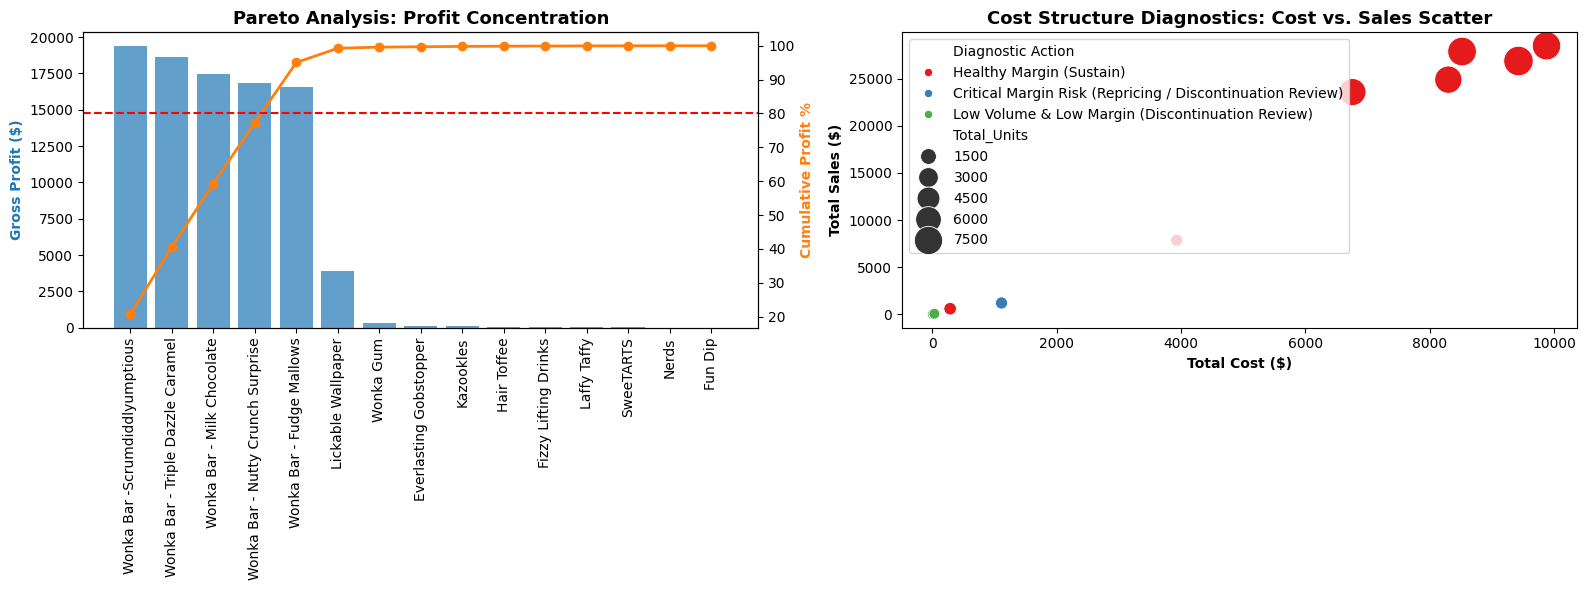

In [63]:
# ==============================================================================
# PARETO ANALYSIS & COST STRUCTURE DIAGNOSTICS
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Pareto Concentration
pareto_df = prod_kpi.sort_values(by='Total_Gross_Profit', ascending=False).reset_index(drop=True)
pareto_df['Cumulative_Profit'] = pareto_df['Total_Gross_Profit'].cumsum()
pareto_df['Cumulative_Profit_%'] = (pareto_df['Cumulative_Profit'] / total_distributor_profit) * 100
pareto_df['Cumulative_Sales_%'] = (pareto_df['Total_Sales'].cumsum() / total_distributor_sales) * 100

top_profit_80_count = (pareto_df['Cumulative_Profit_%'] <= 80).sum() + 1
print(f"Pareto Finding: {top_profit_80_count} of {len(pareto_df)} products ({top_profit_80_count / len(pareto_df) * 100:.1f}%) drive 80% of distributor gross profit.")

# 2. Cost Diagnostics & Action Flags
def assign_action_flag(row):
    if row['Gross Margin (%)'] < 20.0:
        return 'Critical Margin Risk (Repricing / Discontinuation Review)'
    elif row['Gross Margin (%)'] < 50.0 and row['Total_Sales'] < 100:
        return 'Low Volume & Low Margin (Discontinuation Review)'
    elif row['Gross Margin (%)'] < 50.0:
        return 'Cost-Heavy / Pricing Inefficiency (Cost Renegotiation)'
    else:
        return 'Healthy Margin (Sustain)'

prod_kpi['Diagnostic Action'] = prod_kpi.apply(assign_action_flag, axis=1)

print("\n--- ACTION RECOMMENDATIONS TABLE ---")
display(prod_kpi[['Product Name', 'Division', 'Total_Sales', 'Total_Cost', 'Gross Margin (%)', 'Diagnostic Action']]
        .sort_values(by='Gross Margin (%)'))

# 3. Diagnostics Visualizations
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot A: Pareto Chart
ax1 = axes[0]
ax2 = ax1.twinx()
ax1.bar(range(len(pareto_df)), pareto_df['Total_Gross_Profit'], color='#1f77b4', alpha=0.7)
ax2.plot(range(len(pareto_df)), pareto_df['Cumulative_Profit_%'], color='#ff7f0e', marker='o', linewidth=2)
ax2.axhline(80, color='red', linestyle='--', label='80% Cutoff')
ax1.set_xticks(range(len(pareto_df)))
ax1.set_xticklabels(pareto_df['Product Name'], rotation=90)
ax1.set_ylabel('Gross Profit ($)', color='#1f77b4', fontweight='bold')
ax2.set_ylabel('Cumulative Profit %', color='#ff7f0e', fontweight='bold')
ax1.set_title('Pareto Analysis: Profit Concentration', fontsize=13, fontweight='bold')

# Subplot B: Cost vs. Sales Scatter
sns.scatterplot(
    data=prod_kpi,
    x='Total_Cost',
    y='Total_Sales',
    hue='Diagnostic Action',
    size='Total_Units',
    sizes=(60, 450),
    ax=axes[1],
    palette='Set1'
)
axes[1].set_title('Cost Structure Diagnostics: Cost vs. Sales Scatter', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Total Cost ($)', fontweight='bold')
axes[1].set_ylabel('Total Sales ($)', fontweight='bold')

plt.tight_layout()
plt.show()

In [67]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import os

st.set_page_config(
    page_title="Nassau Candy - Profitability & Margin Performance",
    page_icon="🍬",
    layout="wide",
    initial_sidebar_state="expanded"
)

# -----------------------------------------------------------------------------
# CUSTOM CSS: Full-Width Stretch, Tab Gaps, Clean Spacing, Big Fonts
# -----------------------------------------------------------------------------
st.markdown("""
<style>
    /* Main body padding - full screen use */
    .block-container {
        padding-top: 3.2rem !important;
        padding-bottom: 2rem !important;
        padding-left: 2rem !important;
        padding-right: 2rem !important;
        max-width: 100% !important;
    }

    body {
        overflow-x: hidden !important;
    }

    /* 1. SIDEBAR: Compact to remove vertical scrollbar */
    section[data-testid="stSidebar"] {
        overflow: hidden !important;
    }
    section[data-testid="stSidebar"] > div {
        overflow: hidden !important;
        padding-top: 1.2rem !important;
        padding-bottom: 0.5rem !important;
    }
    section[data-testid="stSidebar"] .stMultiSelect,
    section[data-testid="stSidebar"] .stDateInput,
    section[data-testid="stSidebar"] .stSlider,
    section[data-testid="stSidebar"] .stTextInput {
        margin-bottom: -4px !important;
    }
    section[data-testid="stSidebar"] label {
        font-size: 0.86rem !important;
        font-weight: 600 !important;
        margin-bottom: 2px !important;
    }

    /* 2. HEADER: Line-height & Padding Fix (Akshare cut honar nahit) */
    .main-distributor-title {
        font-size: 2.4rem !important;
        font-weight: 800 !important;
        color: #0f172a !important;
        line-height: 1.5 !important;
        padding: 6px 0px !important;
        margin-top: 0.2rem !important;
        margin-bottom: 0.4rem !important;
        display: block !important;
    }

    .sub-distributor-title {
        font-size: 1.15rem !important;
        font-weight: 500 !important;
        color: #475569 !important;
        line-height: 1.4 !important;
        margin-bottom: 1.8rem !important;
        display: block !important;
    }

    /* 3. METRIC CARDS: Big Headings, Full Uncut Numbers */
    div[data-testid="stMetric"] {
        background-color: #f8fafc !important;
        border: 1px solid #e2e8f0 !important;
        padding: 14px 16px !important;
        border-radius: 12px !important;
        box-shadow: 0 1px 3px rgba(0,0,0,0.04) !important;
        min-height: 105px !important;
    }

    div[data-testid="stMetricLabel"] p {
        font-size: 1.05rem !important;
        font-weight: 700 !important;
        color: #1e293b !important;
        margin-bottom: 6px !important;
        text-transform: capitalize !important;
    }

    div[data-testid="stMetricValue"] > div {
        font-size: 1.55rem !important;
        font-weight: 800 !important;
        color: #0f172a !important;
        white-space: nowrap !important;
        overflow: visible !important;
        text-overflow: clip !important;
        line-height: 1.25 !important;
    }

    /* 4. TABS: Spread evenly across screen with good distance */
    .stTabs [data-baseweb="tab-list"] {
        display: flex !important;
        justify-content: space-between !important;
        width: 100% !important;
        margin-top: 1.2rem !important;
        margin-bottom: 1.6rem !important;
        border-bottom: 2px solid #e2e8f0 !important;
    }
    .stTabs [data-baseweb="tab"] {
        flex: 1 !important;
        text-align: center !important;
        font-size: 1.02rem !important;
        font-weight: 600 !important;
        padding: 12px 18px !important;
    }
</style>
""", unsafe_allow_html=True)

# -----------------------------------------------------------------------------
# 1. DATA CACHING & PREPARATION
# -----------------------------------------------------------------------------
@st.cache_data
def load_data():
    csv_candidates = [
        'Nassau Candy Distributor.csv',
        '/content/Nassau Candy Distributor.csv'
    ]
    target_csv = next((f for f in csv_candidates if os.path.exists(f)), None)

    if not target_csv:
        st.error("Error: 'Nassau Candy Distributor.csv' file not found.")
        st.stop()

    df = pd.read_csv(target_csv)

    str_cols = ['Division', 'Region', 'Country/Region', 'City', 'State/Province', 'Product ID', 'Product Name', 'Ship Mode']
    for col in str_cols:
        if col in df.columns:
            df[col] = df[col].astype(str).str.strip()

    df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
    df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)
    df['Gross Margin (%)'] = (df['Gross Profit'] / df['Sales']) * 100
    df['Profit per Unit'] = df['Gross Profit'] / df['Units']

    return df

df_raw = load_data()

# -----------------------------------------------------------------------------
# 2. SIDEBAR USER CONTROLS
# -----------------------------------------------------------------------------
st.sidebar.markdown("### 🍬 User Controls")

min_date = df_raw['Order Date'].min().date()
max_date = df_raw['Order Date'].max().date()
date_range = st.sidebar.date_input("Date Range Selector", (min_date, max_date), min_value=min_date, max_value=max_date)

all_divisions = sorted(df_raw['Division'].unique().tolist())
selected_divisions = st.sidebar.multiselect("Division Filter", options=all_divisions, default=all_divisions)

margin_threshold = st.sidebar.slider("Margin Threshold Slider (%)", min_value=0.0, max_value=100.0, value=50.0, step=1.0)
search_query = st.sidebar.text_input("Product Search", placeholder="e.g. Wonka, Kazookles...")

# Apply Filters
if isinstance(date_range, (tuple, list)) and len(date_range) == 2:
    start_d, end_d = pd.to_datetime(date_range[0]), pd.to_datetime(date_range[1])
    fdf = df_raw[(df_raw['Order Date'] >= start_d) & (df_raw['Order Date'] <= end_d)].copy()
else:
    fdf = df_raw.copy()

fdf = fdf[fdf['Division'].isin(selected_divisions)]

if search_query.strip():
    fdf = fdf[fdf['Product Name'].str.contains(search_query, case=False, na=False)]

# -----------------------------------------------------------------------------
# 3. HEADER & METRIC CARDS
# -----------------------------------------------------------------------------
st.markdown('<div class="main-distributor-title">🍬 Nassau Candy Distributor</div>', unsafe_allow_html=True)
st.markdown('<div class="sub-distributor-title">Product Line Profitability & Margin Performance Analysis</div>', unsafe_allow_html=True)

kpi_sales = fdf['Sales'].sum()
kpi_profit = fdf['Gross Profit'].sum()
kpi_cogs = fdf['Cost'].sum()
kpi_units = fdf['Units'].sum()
kpi_margin = (kpi_profit / kpi_sales * 100) if kpi_sales > 0 else 0

# 5 Balanced KPI cards with spacing
k1, k2, k3, k4, k5 = st.columns(5)
k1.metric("Gross Revenue", f"${kpi_sales:,.2f}")
k2.metric("Gross Profit", f"${kpi_profit:,.2f}")
k3.metric("Total COGS", f"${kpi_cogs:,.2f}")
k4.metric("Average Gross Margin", f"{kpi_margin:.2f}%")
k5.metric("Total Units Sold", f"{kpi_units:,}")

st.write("")

# -----------------------------------------------------------------------------
# 4. DASHBOARD MODULES (FULL SPREAD & PROPER GAP)
# -----------------------------------------------------------------------------
tab1, tab2, tab3, tab4 = st.tabs([
    "📊 Product Profitability Overview",
    "🏢 Division Performance Dashboard",
    "🔬 Cost vs Margin Diagnostics",
    "🎯 Profit Concentration Analysis"
])

# Product Aggregation
prod_kpi = fdf.groupby(['Product ID', 'Product Name', 'Division']).agg(
    Revenue=('Sales', 'sum'),
    Cost=('Cost', 'sum'),
    Gross_Profit=('Gross Profit', 'sum'),
    Units=('Units', 'sum')
).reset_index()

prod_kpi['Gross Margin (%)'] = (prod_kpi['Gross_Profit'] / prod_kpi['Revenue']) * 100
prod_kpi['Profit per Unit'] = prod_kpi['Gross_Profit'] / prod_kpi['Units']
prod_kpi['Profit Contribution (%)'] = (prod_kpi['Gross_Profit'] / kpi_profit * 100) if kpi_profit > 0 else 0

# -----------------------------------------------------------------------------
# MODULE 1: Product Profitability Overview
# -----------------------------------------------------------------------------
with tab1:
    # 2 Columns with full width and clear margin
    c_p1, c_p2 = st.columns([1.1, 1], gap="large")
    with c_p1:
        st.markdown("#### Product-Level Margin Leaderboard")
        fig_leaderboard = px.bar(
            prod_kpi.sort_values(by='Gross Margin (%)', ascending=True),
            x='Gross Margin (%)', y='Product Name', orientation='h',
            color='Gross Margin (%)', color_continuous_scale='Blues',
            text=prod_kpi.sort_values(by='Gross Margin (%)', ascending=True)['Gross Margin (%)'].apply(lambda x: f"{x:.1f}%")
        )
        # l=190 ensures product names are never cut off or overlapping the chart
        fig_leaderboard.update_layout(
            height=480,
            margin=dict(l=190, r=20, t=10, b=20),
            xaxis_title="Gross Margin (%)",
            yaxis_title="",
            coloraxis_showscale=False
        )
        st.plotly_chart(fig_leaderboard, use_container_width=True)
    with c_p2:
        st.markdown("#### Profit Contribution Charts")
        fig_pie = px.pie(
            prod_kpi, names='Product Name', values='Gross_Profit',
            hole=0.45, color_discrete_sequence=px.colors.qualitative.Prism
        )
        fig_pie.update_traces(textposition='inside', textinfo='percent+label')
        fig_pie.update_layout(
            height=480,
            margin=dict(l=10, r=10, t=10, b=20),
            legend=dict(orientation="v", yanchor="middle", y=0.5, xanchor="left", x=1.02)
        )
        st.plotly_chart(fig_pie, use_container_width=True)

# -----------------------------------------------------------------------------
# MODULE 2: Division Performance Dashboard
# -----------------------------------------------------------------------------
with tab2:
    div_summary = fdf.groupby('Division').agg(
        Revenue=('Sales', 'sum'), Cost=('Cost', 'sum'),
        Gross_Profit=('Gross Profit', 'sum'), Units=('Units', 'sum')
    ).reset_index()
    div_summary['Gross Margin (%)'] = (div_summary['Gross_Profit'] / div_summary['Revenue']) * 100
    div_summary['Revenue Share (%)'] = (div_summary['Revenue'] / kpi_sales * 100) if kpi_sales > 0 else 0
    div_summary['Profit Share (%)'] = (div_summary['Gross_Profit'] / kpi_profit * 100) if kpi_profit > 0 else 0

    c_d1, c_d2 = st.columns(2, gap="large")
    with c_d1:
        st.markdown("#### Revenue vs Profit Comparison")
        fig_div_bar = go.Figure(data=[
            go.Bar(name='Revenue ($)', x=div_summary['Division'], y=div_summary['Revenue'], marker_color='#1f77b4'),
            go.Bar(name='Gross Profit ($)', x=div_summary['Division'], y=div_summary['Gross_Profit'], marker_color='#2ca02c')
        ])
        fig_div_bar.update_layout(barmode='group', height=450, margin=dict(l=20, r=20, t=20, b=20), yaxis_title="USD ($)")
        st.plotly_chart(fig_div_bar, use_container_width=True)
    with c_d2:
        st.markdown("#### Margin Distribution by Division")
        fig_box = px.box(fdf, x='Division', y='Gross Margin (%)', color='Division', points='outliers')
        fig_box.update_layout(height=450, margin=dict(l=20, r=20, t=20, b=20), showlegend=False)
        st.plotly_chart(fig_box, use_container_width=True)

# -----------------------------------------------------------------------------
# MODULE 3: Cost vs Margin Diagnostics
# -----------------------------------------------------------------------------
with tab3:
    prod_kpi['Risk Flag'] = np.where(
        prod_kpi['Gross Margin (%)'] < margin_threshold,
        f'Margin Risk (< {margin_threshold:.0f}%)',
        'Healthy Margin'
    )
    st.markdown("#### Cost-Sales Scatter Plots")
    fig_scatter = px.scatter(
        prod_kpi, x='Cost', y='Revenue', size='Units', color='Risk Flag',
        hover_name='Product Name',
        hover_data=['Division', 'Gross Margin (%)', 'Profit per Unit'],
        color_discrete_map={'Healthy Margin': '#22c55e', f'Margin Risk (< {margin_threshold:.0f}%)': '#ef4444'},
        title=f"Cost vs. Revenue Scatter Plot (Risk Threshold: {margin_threshold:.0f}%)"
    )
    fig_scatter.update_layout(height=460, margin=dict(l=20, r=20, t=35, b=20), xaxis_title="Total Cost ($)", yaxis_title="Total Revenue ($)")
    st.plotly_chart(fig_scatter, use_container_width=True)

    st.markdown("#### Margin Risk Flags")
    risk_products = prod_kpi[prod_kpi['Gross Margin (%)'] < margin_threshold].sort_values(by='Gross Margin (%)')
    if not risk_products.empty:
        st.dataframe(
            risk_products[['Product Name', 'Division', 'Revenue', 'Cost', 'Gross_Profit', 'Gross Margin (%)', 'Profit per Unit']]
            .style.format({
                'Revenue': '${:,.2f}',
                'Cost': '${:,.2f}',
                'Gross_Profit': '${:,.2f}',
                'Gross Margin (%)': '{:.2f}%',
                'Profit per Unit': '${:,.2f}'
            }),
            use_container_width=True
        )
    else:
        st.success(f"No products found below the {margin_threshold:.0f}% margin threshold.")

# -----------------------------------------------------------------------------
# MODULE 4: Profit Concentration Analysis
# -----------------------------------------------------------------------------
with tab4:
    pareto_df = prod_kpi.sort_values(by='Gross_Profit', ascending=False).reset_index(drop=True)
    pareto_df['Cumulative_Profit_%'] = (pareto_df['Gross_Profit'].cumsum() / kpi_profit * 100) if kpi_profit > 0 else 0

    st.markdown("#### Pareto Charts")
    fig_pareto = go.Figure()
    fig_pareto.add_trace(go.Bar(x=pareto_df['Product Name'], y=pareto_df['Gross_Profit'], name='Gross Profit ($)', marker_color='#2563eb'))
    fig_pareto.add_trace(go.Scatter(x=pareto_df['Product Name'], y=pareto_df['Cumulative_Profit_%'], name='Cumulative Profit %', yaxis='y2', mode='lines+markers', line=dict(color='#f97316', width=2.5)))
    fig_pareto.add_hline(y=80, line_dash="dash", line_color="red", yref='y2', annotation_text="80% Threshold")
    fig_pareto.update_layout(
        height=450, margin=dict(l=20, r=20, t=30, b=20),
        yaxis=dict(title="Gross Profit ($)"),
        yaxis2=dict(title="Cumulative %", overlaying='y', side='right', range=[0, 105]),
        xaxis_tickangle=-30
    )
    st.plotly_chart(fig_pareto, use_container_width=True)

    st.markdown("#### Dependency Indicators")
    top_80_count = (pareto_df['Cumulative_Profit_%'] <= 80).sum() + 1
    total_skus = len(pareto_df)
    st.info(
        f"**Profit Concentration Finding:** Exactly **{top_80_count} of {total_skus} products** "
        f"({top_80_count / total_skus * 100:.1f}% of catalog) drive **80%** of Nassau Candy Distributor's total gross profit."
    )

Writing app.py


In [68]:
!pkill -9 -f streamlit
!nohup streamlit run app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true --server.enableCORS false --server.enableXsrfProtection false > streamlit.log 2>&1 &

In [69]:
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb > /dev/null 2>&1

!pkill -9 -f streamlit
!pkill -9 -f cloudflared

!nohup streamlit run app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.headless true \
    --server.enableCORS false \
    --server.enableXsrfProtection false > streamlit.log 2>&1 &

!nohup cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate > tunnel.log 2>&1 &

import time, re
time.sleep(6)
with open("tunnel.log", "r") as f:
    log_text = f.read()
    links = re.findall(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", log_text)
    if links:
        print("=" * 65)
        print("👉 Direct Full-Screen Streamlit Link:")
        print(links[-1])
        print("=" * 65)
    else:
        print("Your Tunnel is start. please check!")

👉 Direct Full-Screen Streamlit Link:
https://brand-frequencies-purchased-psychiatry.trycloudflare.com
